# Step 1: Data, cleaning, splits and EDA

Reads the saved reports of `pipeline/notebooks/01–05` and checks the final splits. Details: `docs/steps/01_data_and_eda.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import nbutils as U
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("model prediction groups found:", len(list(U.PRED_DIR.glob("*/sarc_random__test.parquet"))))

model prediction groups found: 22


## 1.1 Cleaning
The primary corpus is SARC (balanced Kaggle release). Each cleaning step and how many rows it removed:

In [2]:
# Cleaning steps for SARC
rep = U.read_json(U.OFFICIAL / "results/cleaning/reddit_sarc_balanced_full_cleaning_report.json")
print(f"rows in {rep['rows_in']:,} -> rows out {rep['rows_out']:,} ({rep['retained_pct']}% kept)")
pd.DataFrame(rep["steps"])[["step", "reason", "removed", "rows_remaining"]]

rows in 1,010,826 -> rows out 913,769 (90.4% kept)


,step,reason,removed,rows_remaining
0,1,empty / [deleted] / [removed] comment,63,1010763
1,2,empty after markup/leak removal,79,1010684
2,3,fewer than 2 words,44173,966511
3,4,more than 300 words / 2000 chars,33,966478
4,5,non-English (heuristic + langdetect),3034,963444
5,6,exact dup (comment+label+parent),441,963003
6,7,same text carries both labels,28881,934122
7,8,"near-dup (normalised text, any parent)",20353,913769


## 1.2 Splits
Three split schemes partition the same cleaned rows. `sarc_random` is the default; `sarc_subreddit` keeps train and test communities disjoint and is the stress test used throughout. The four supplementary sets are only used to test transfer.

In [3]:
# Split sizes and class balance
from load import load_split
rows = []
for ds in ["sarc_random", "sarc_subreddit", "sarc_temporal", "figlang_reddit", "figlang_twitter", "tweeteval_irony", "news_headlines"]:
    r = {"split set": ds}
    for part in ["train", "val", "test"]:
        df = load_split(ds, part, columns=["label"])
        r[part] = len(df); r[f"{part} % sarcastic"] = round(100 * df["label"].mean(), 1)
    rows.append(r)
splits = pd.DataFrame(rows); splits

,split set,train,train % sarcastic,val,val % sarcastic,test,test % sarcastic
0,sarc_random,639638,50.9,137066,50.9,137065,51.1
1,sarc_subreddit,639838,51.1,135123,51.2,135534,49.9
2,sarc_temporal,484447,53.8,182441,50.4,242091,45.8
3,figlang_reddit,3729,50.0,659,50.1,1756,49.7
4,figlang_twitter,4028,52.6,711,52.6,1715,47.5
5,tweeteval_irony,2853,50.5,950,48.0,780,39.7
6,news_headlines,19862,47.5,4256,47.5,4257,47.5


In [4]:
# Leakage audit
ver = U.read_json(U.OFFICIAL / "results/splits/split_verification.json")
audit = pd.DataFrame([{"dataset": a["dataset"], "status": a["status"], "checks": len(a["checks"])} for a in ver["audit"]])
print("leakage-audit failures:", ver["audit_failures"]); audit

leakage-audit failures: 0


,dataset,status,checks
0,sarc_random,PASS,6
1,sarc_subreddit,PASS,9
2,sarc_temporal,PASS,6
3,figlang_reddit,PASS,3
4,figlang_twitter,PASS,3
5,news_headlines,PASS,3
6,tweeteval_irony,PASS,3


## 1.3 Exploratory analysis — key statistics

In [5]:
# EDA statistics and surface markers
eda = U.read_json(U.OFFICIAL / "results/eda/eda_statistics.json")
print("primary rows:", eda["primary_rows"], "| sarcastic rate:", eda["primary_sarcastic_rate"])
print("median words (not / sarcastic):", eda["length_words"]["median"])
print("subreddits:", eda["n_subreddits"], "| sarcasm rate range across subreddits:",
      eda["subreddit_sarcasm_rate_spread"]["min"], "-", eda["subreddit_sarcasm_rate_spread"]["max"])
markers = pd.DataFrame(eda["marker_presence_rates_pct"])[["marker", "rate_not", "rate_sarc", "lift"]]
markers.sort_values("lift", ascending=False)

primary rows: 913769 | sarcastic rate: 0.5093
median words (not / sarcastic): {'0': 9.0, '1': 9.0}
subreddits: 13970 | sarcasm rate range across subreddits: 0.0805 - 0.7906


,marker,rate_not,rate_sarc,lift
0,Exclamation !,4.897,13.767,2.811
1,Interjection (oh/wow),13.633,26.869,1.971
2,Elongation (sooo),0.969,1.439,1.485
3,Repeated punct !!,8.027,8.451,1.053
4,Ellipsis ...,8.004,8.414,1.051
5,ALL-CAPS word,11.297,11.869,1.051
6,Question ?,12.602,11.153,0.885
7,Scare quotes,4.292,2.867,0.668
8,Emoji,0.000,0.000,NaN


In [6]:
# Most distinctive tokens
tok = pd.concat([pd.DataFrame(eda["log_odds_top_sarcastic"]).head(12).assign(direction="sarcastic"),
                 pd.DataFrame(eda["log_odds_top_not_sarcastic"]).head(12).assign(direction="not sarcastic")])
tok[["direction", "token", "z", "n_sarc", "n_not"]]

,direction,token,z,n_sarc,n_not
0,sarcastic,yeah,72.24,13728,3765
1,sarcastic,because,68.68,16049,5811
2,sarcastic,obviously,44.29,3887,445
3,sarcastic,all,41.76,13832,7974
4,sarcastic,totally,40.82,3356,459
5,sarcastic,yes,37.12,5054,1935
6,sarcastic,clearly,35.93,2654,409
7,sarcastic,we,35.23,10615,6279
8,sarcastic,right,31.06,6531,3534
9,sarcastic,oh,30.70,4004,1701


## 1.4 Figures produced by the EDA notebook

**F01_class_balance**

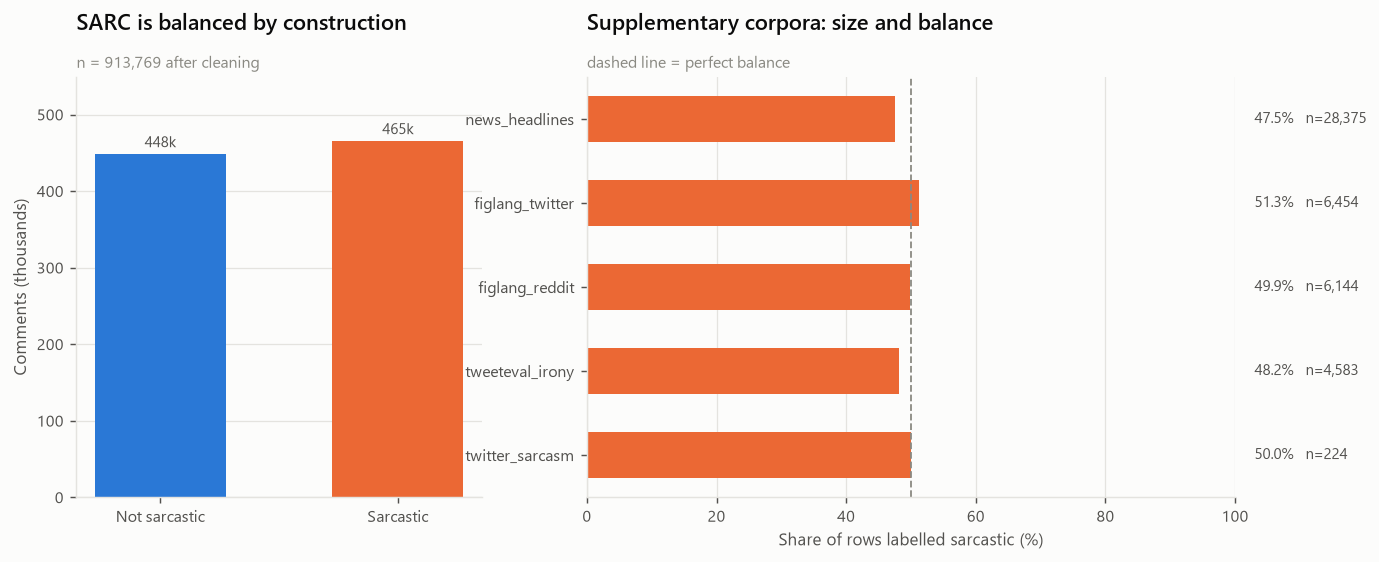

**F02_length_distribution**

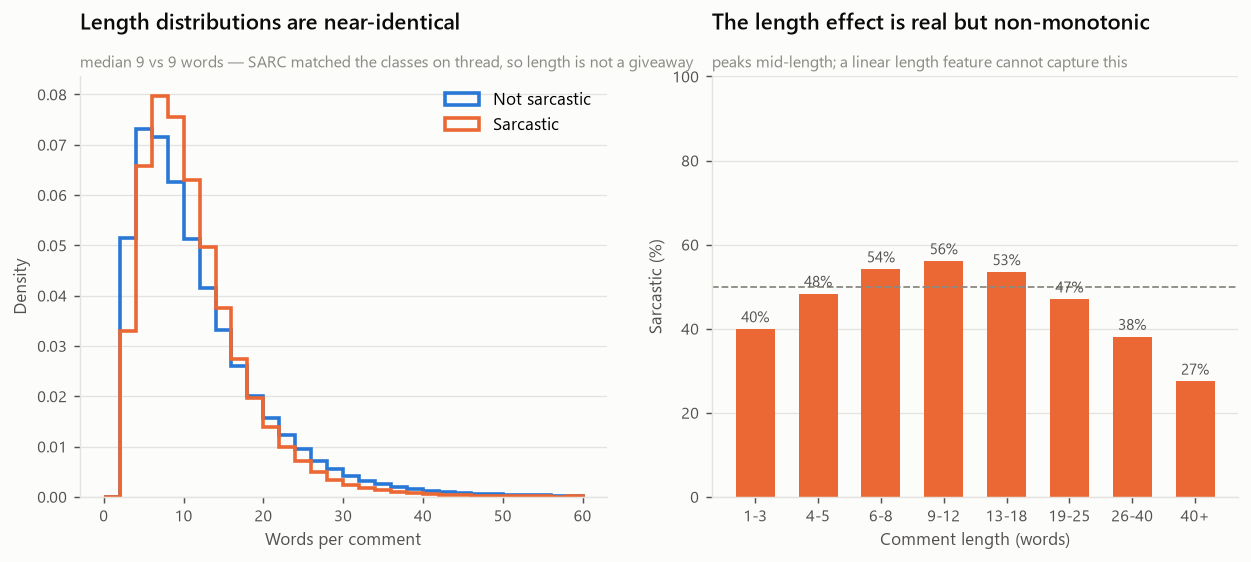

**F03_linguistic_markers**

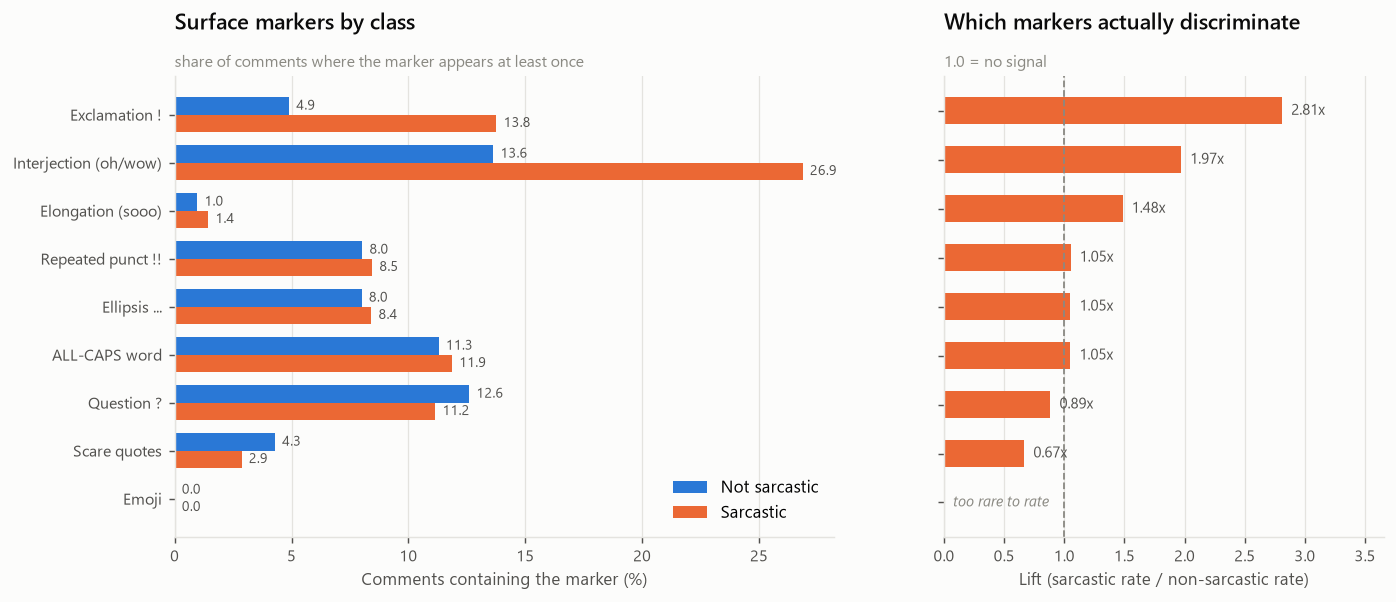

**F07_parent_context**

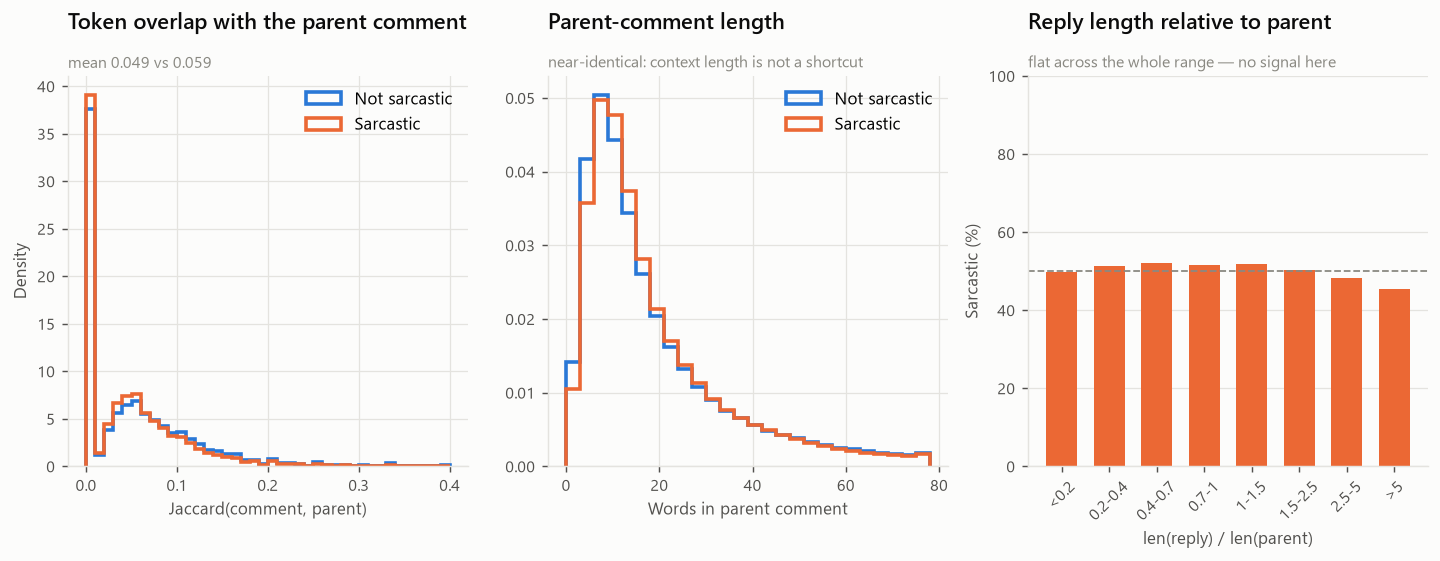

**F08_log_odds_tokens**

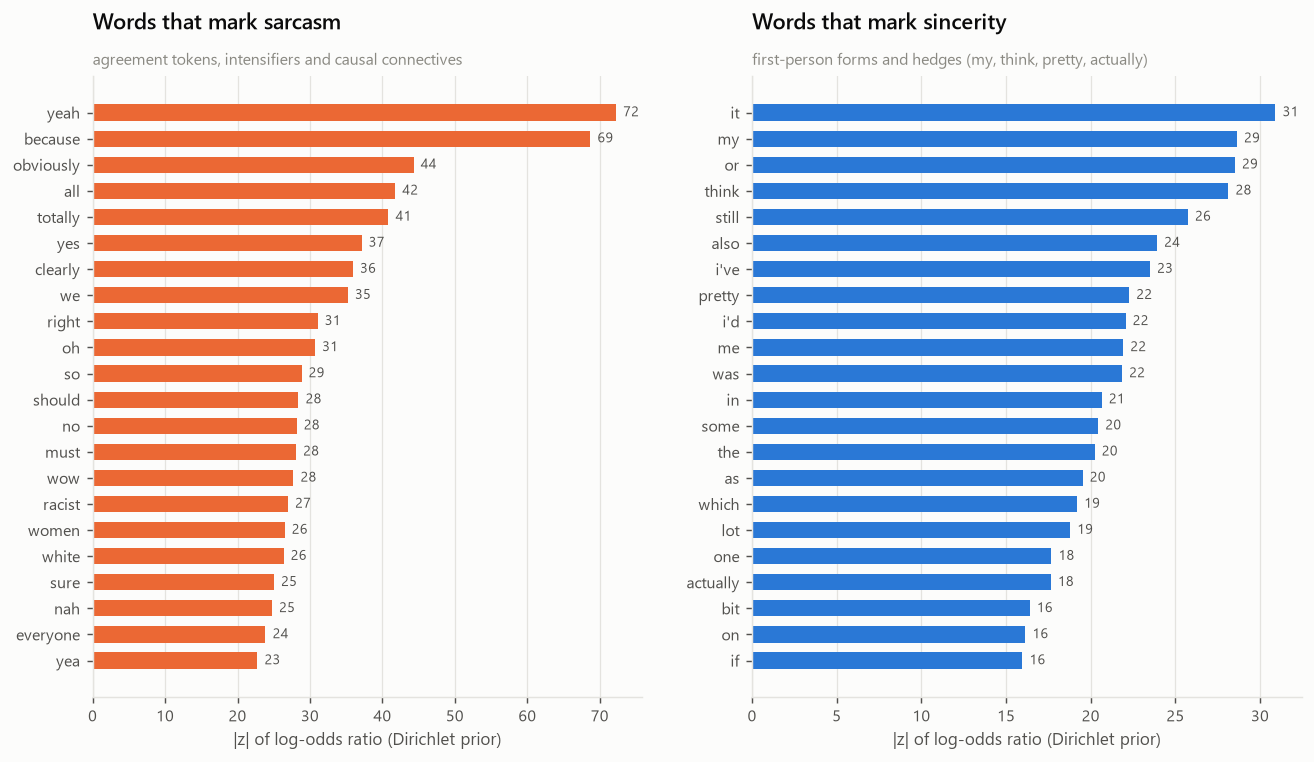

**F09_cross_corpus**

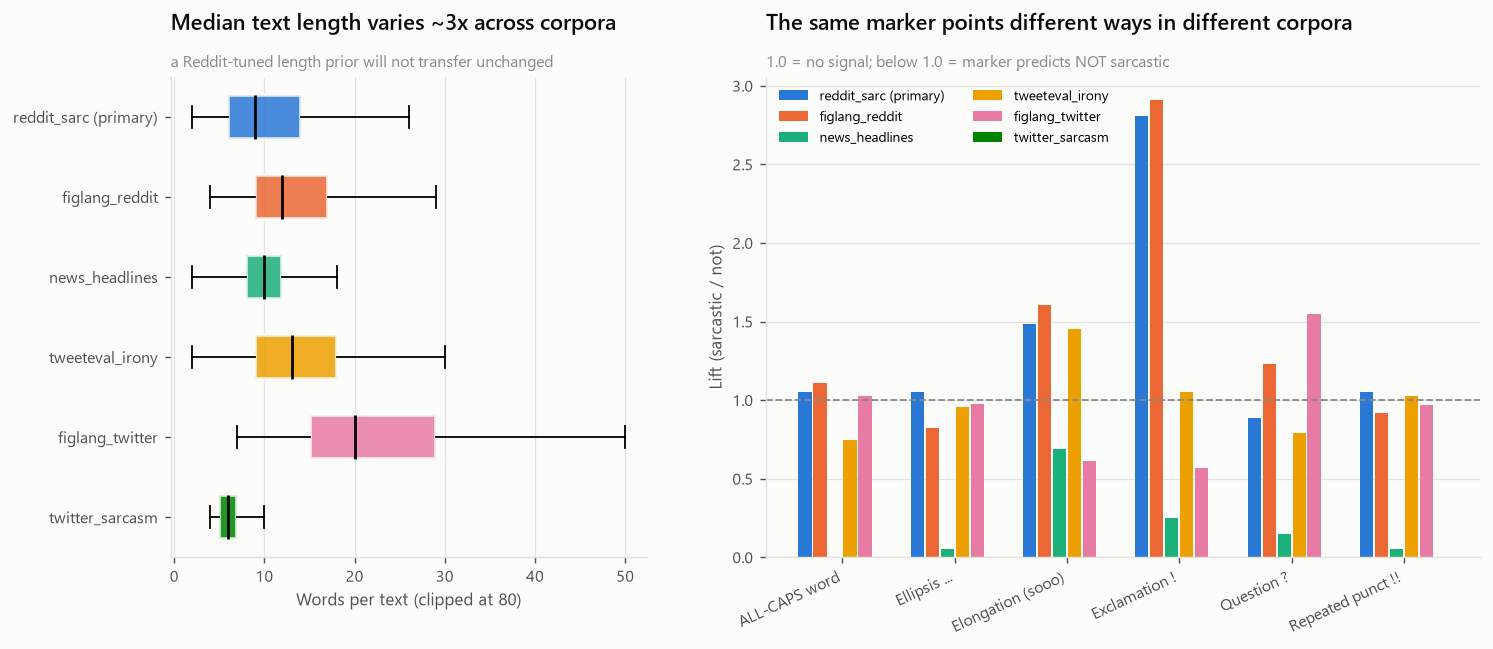

In [7]:
# EDA figures
for f in ["F01_class_balance", "F02_length_distribution", "F03_linguistic_markers", "F07_parent_context", "F08_log_odds_tokens", "F09_cross_corpus"]:
    display(Markdown(f"**{f}**")); display(Image(filename=str(U.OFFICIAL / "figures/eda" / f"{f}.png"), width=720))

## 1.5 Takeaways

- SARC is balanced (≈51% sarcastic) and has no label leakage, but 2.9% of texts appear under both labels, which caps achievable accuracy.
- Length is not a shortcut (median 9 words in both classes). Exclamation marks and interjections are the only strong surface markers.
- Sarcastic vocabulary is "mock agreement": *yeah, because, obviously, totally, sure*.
- Subreddit strongly predicts the label but mostly reflects the `/s` convention, so later steps do not rely on it.